# Experiment 1 — First-order dynamics

This experiment compares `FirstOrderDynamics` using different velocity response time constants. The flight plan, guidance law and all other simulation parameters remain unchanged.

In [7]:
from pathlib import Path

from IPython.display import Image, display

from musas.airspace import Airspace
from musas.algorithms import FirstOrderDynamics, WaypointGuidance
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    animate_dataset,
    plot_dataset,
)
from musas.simulation.metrics import (
    actual_distance,
    actual_flight_time,
    planned_distance,
    planned_flight_time,
)

OUTPUT_DIRECTORY = Path("outputs") / "output_exp1"
DATASET_DIRECTORY = OUTPUT_DIRECTORY / "datasets"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
DATASET_DIRECTORY.mkdir(exist_ok=True)

## Scenario configuration

The route has sharp turns so that the effect of the response time is visible. The maximum acceleration is deliberately high to keep it from dominating the comparison.

In [8]:
RESPONSE_TIMES = [0.0, 0.5, 1.5, 4.0]
SIMULATION_END = 70.0
FLIGHT_UPDATE_INTERVAL = 0.1
RECORD_INTERVAL = 0.2
MAX_ACCELERATION = 100.0

def create_flight_plan():
    return FlightPlan([
        Waypoint(0.0, 0.0, 100.0, 2.0),
        Waypoint(80.0, 0.0, 100.0, 12.0),
        Waypoint(80.0, 60.0, 100.0, 22.0),
        Waypoint(0.0, 60.0, 100.0, 32.0),
        Waypoint(0.0, 0.0, 100.0, 42.0),
    ])

## Run one simulation per response time

Each execution is recorded in its own SQLite dataset. The built-in visualization and metric functions consume these datasets directly.

In [9]:
def response_time_label(response_time):
    return str(response_time).replace(".", "_")

def run_case(response_time):
    dataset_path = (
        DATASET_DIRECTORY
        / f"first_order_tau_{response_time_label(response_time)}.sqlite"
    )
    simulation = Simulation(
        airspace=Airspace(),
        flight_update_interval=FLIGHT_UPDATE_INTERVAL,
        trajectory_record_interval=RECORD_INTERVAL,
        message_types_to_log=(),
        dataset_path=dataset_path,
        dataset_metadata={
            "experiment": "first_order_dynamics",
            "velocity_time_constant": response_time,
        },
        overwrite_dataset=True,
    )
    simulation.add_uav(
        name="UAV 1",
        flight_plan=create_flight_plan(),
        dynamics_algorithm=FirstOrderDynamics(
            max_acceleration=MAX_ACCELERATION,
            velocity_time_constant=response_time,
        ),
        guidance_algorithm=WaypointGuidance(
            min_speed=0.0,
            max_speed=14.0,
        ),
        waypoint_acceptance_radius=2.0,
    )
    simulation.run(until=SIMULATION_END)
    simulation.close()
    return dataset_path

dataset_paths = {
    response_time: run_case(response_time)
    for response_time in RESPONSE_TIMES
}
dataset_paths

{0.0: PosixPath('outputs/output_exp1/datasets/first_order_tau_0_0.sqlite'),
 0.5: PosixPath('outputs/output_exp1/datasets/first_order_tau_0_5.sqlite'),
 1.5: PosixPath('outputs/output_exp1/datasets/first_order_tau_1_5.sqlite'),
 4.0: PosixPath('outputs/output_exp1/datasets/first_order_tau_4_0.sqlite')}

## Built-in metrics

The planned values are identical in every case. The actual distance and flight time reveal the additional motion caused by slower dynamic response.

In [10]:
print(
    f"{'tau (s)':>8} {'planned dist.':>15} {'actual dist.':>14} "
    f"{'planned time':>14} {'actual time':>13}"
)
for response_time, dataset_path in dataset_paths.items():
    with SimulationDataset(dataset_path) as dataset:
        planned_dist = planned_distance(dataset, "UAV 1")
        actual_dist = actual_distance(dataset, "UAV 1")
        planned_time = planned_flight_time(dataset, "UAV 1")
        actual_time = actual_flight_time(dataset, "UAV 1")
    actual_distance_text = (
        "not completed" if actual_dist is None else f"{actual_dist:.2f}"
    )
    actual_time_text = (
        "not completed" if actual_time is None else f"{actual_time:.1f}"
    )
    print(
        f"{response_time:8.1f} {planned_dist:15.2f} {actual_distance_text:>14} "
        f"{planned_time:14.1f} {actual_time_text:>13}"
    )

 tau (s)   planned dist.   actual dist.   planned time   actual time
     0.0          280.00         270.92           40.0          39.7
     0.5          280.00         277.54           40.0          39.7
     1.5          280.00         293.57           40.0          39.8
     4.0          280.00         417.42           40.0          57.0


## Flight plan and real trajectory

The following figures are generated by the simulator's built-in `plot_dataset()` function.

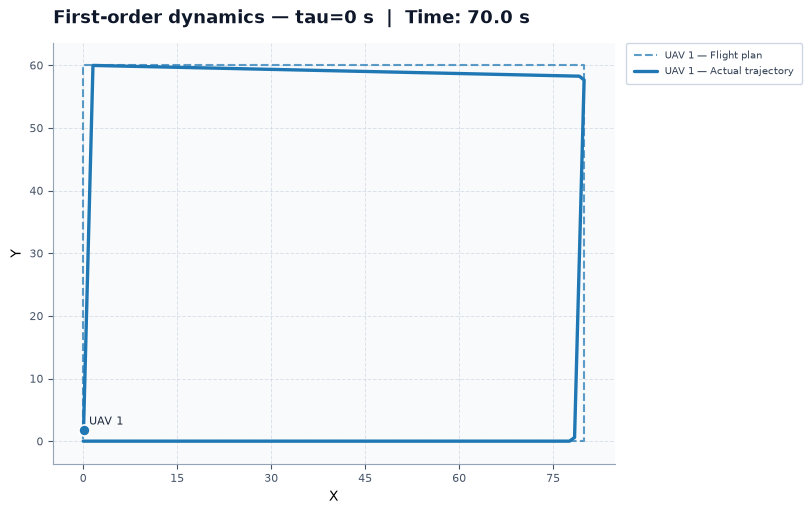

Saved: outputs/output_exp1/trajectory_tau_0_0.png


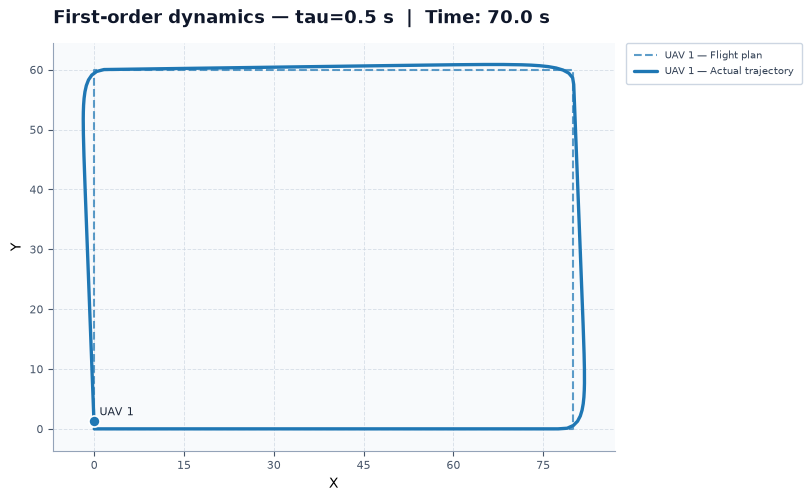

Saved: outputs/output_exp1/trajectory_tau_0_5.png


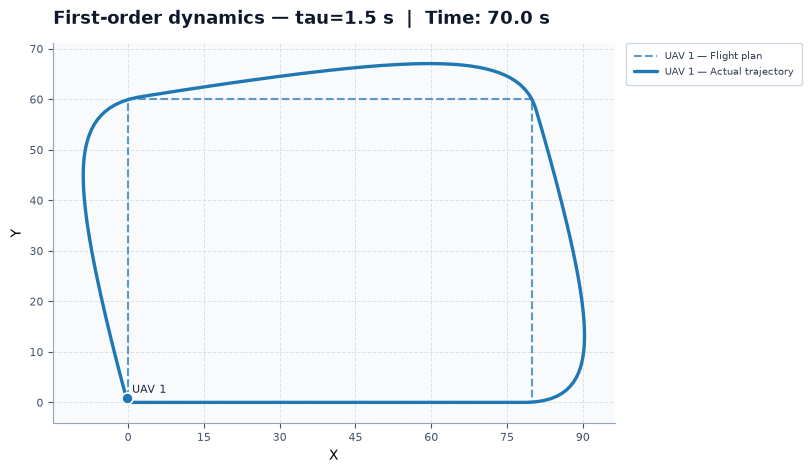

Saved: outputs/output_exp1/trajectory_tau_1_5.png


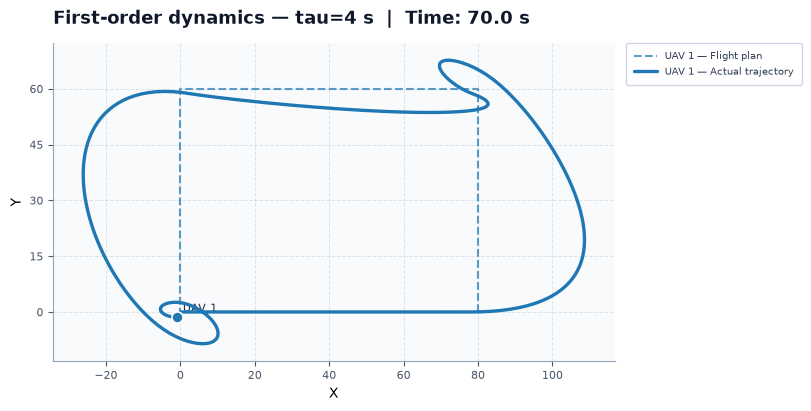

Saved: outputs/output_exp1/trajectory_tau_4_0.png


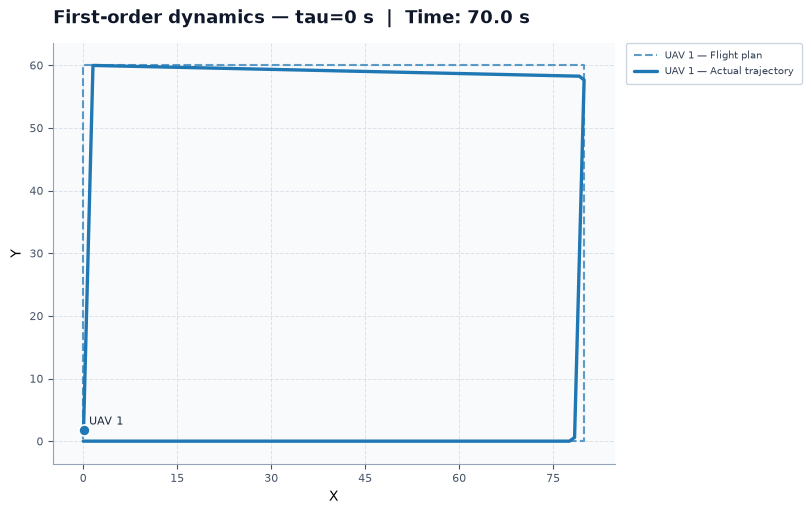

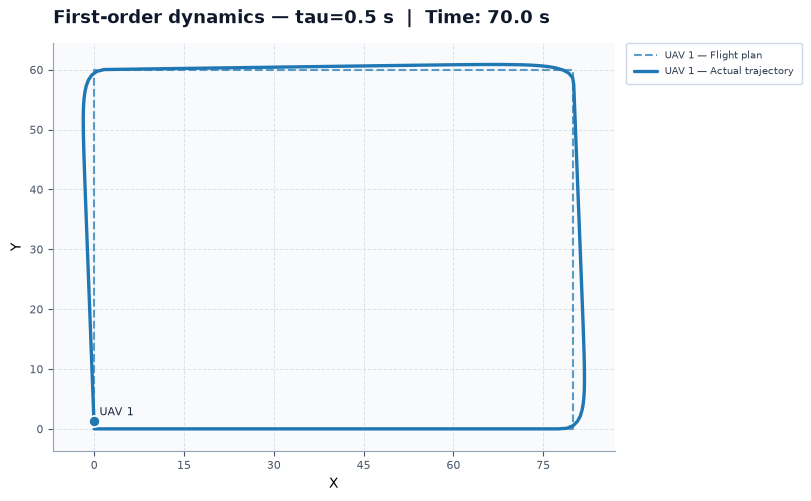

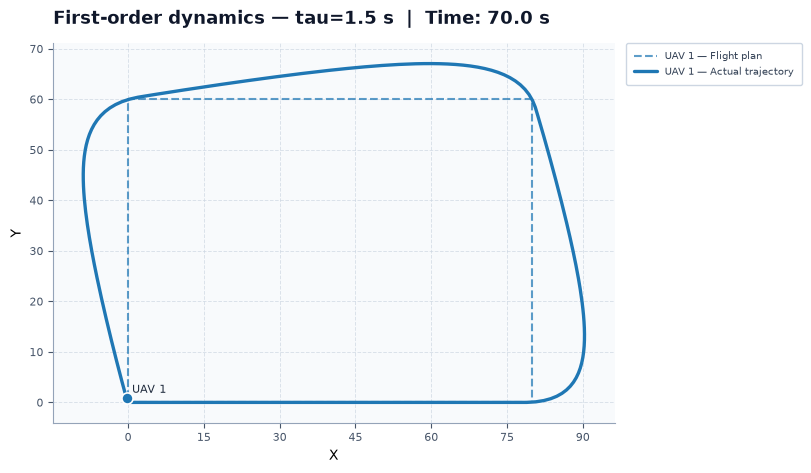

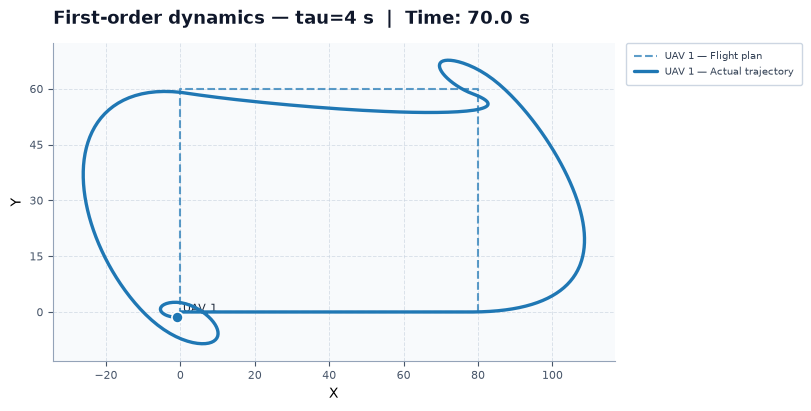

In [11]:
def visualization_config(response_time):
    return VisualizationConfig(
        uav_names=("UAV 1",),
        view="xy",
        show_real_trajectories=True,
        show_current_positions=True,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_tracks=False,
        show_geofences=False,
        show_wind_zones=False,
        show_obstacles=False,
        frame_step=1.0,
        figure_size=(8.0, 6.0),
        title=f"First-order dynamics — tau={response_time:g} s",
    )

for response_time, dataset_path in dataset_paths.items():
    figure_path = (
        OUTPUT_DIRECTORY
        / f"trajectory_tau_{response_time_label(response_time)}.png"
    )
    figure = plot_dataset(
        dataset_path=dataset_path,
        config=visualization_config(response_time),
        timestamp=SIMULATION_END,
        output_path=figure_path,
    )
    display(figure)
    print("Saved:", figure_path)

## Animations

The animations are generated by the simulator's built-in `animate_dataset()` function.

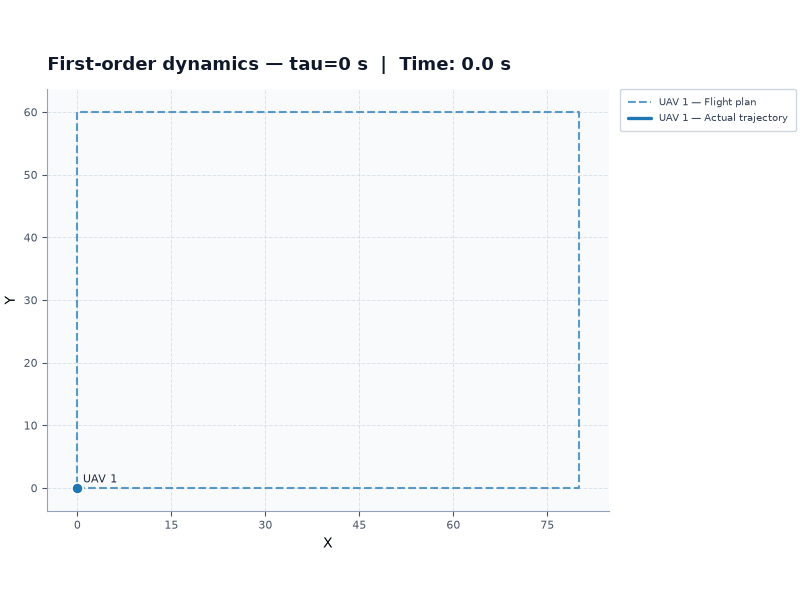

Saved: outputs/output_exp1/animation_tau_0_0.gif


KeyboardInterrupt: 

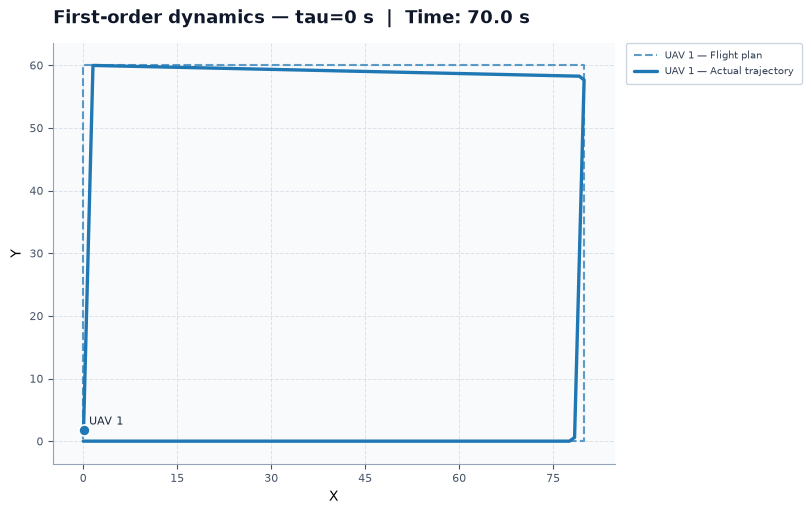

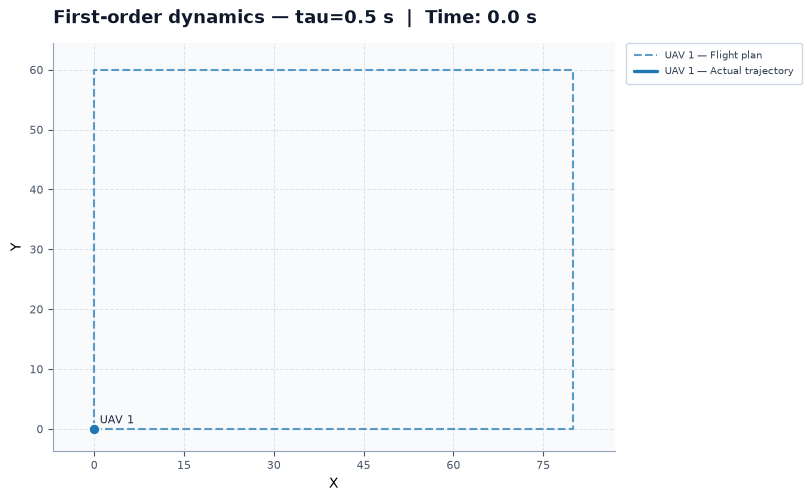

In [12]:
for response_time, dataset_path in dataset_paths.items():
    animation_path = (
        OUTPUT_DIRECTORY
        / f"animation_tau_{response_time_label(response_time)}.gif"
    )
    animate_dataset(
        dataset_path=dataset_path,
        config=visualization_config(response_time),
        output_path=animation_path,
        fps=5.0,
        dpi=100,
    )
    display(Image(filename=animation_path))
    print("Saved:", animation_path)

## Interpretation

Larger time constants make the actual velocity react more slowly to guidance commands. The difference is particularly visible at departure and around sharp turns. The observed trajectory represents the closed-loop interaction between the guidance law and the first-order UAV dynamics.